# GARPOS Notebook 
### This notebook demonstrates how to run the [GARPOS](https://github.com/s-watanabe-jhod/garpos) GNSS-A processing software in the EarthScope GeoLab cloud environment.  
11-07-2025

### GeoLab Basics

GeoLab is the name of EarthScope's Jupyter Hub, which allows users to run code via Jupyter notebooks (or in a terminal) on EarthScope resources in AWS.  

The `sfg-geolab` image comes pre-loaded with the software needed to process GNSS-A data. Each user has their own home directory `/home/jovyan` that is mounted to 
the image and any files kept there are accessibile only to that user and remain during future sessions.  

### Data 
Currently, we have pre-processed `cascadia-gorda` data and stored the shotdata in an S3 bucket accessible to users authorized to use the `s3-seafloor` role.  

Please contact mike.gottlieb@earthscope.org to request access to this role.

Raw data is available to anyone with an earthscope account via authenticated https from [https://data.earthscope.org/archive/seafloor](https://data.earthscope.org/archive/seafloor).

### Metadata
In order to simplify our interactions with the various metadata formats, we are translating all metadata into `site` and `vessel` json. We store and load these metadata from the S3 archive [https://data.earthscope.org/archive/seafloor/metadata](https://data.earthscope.org/archive/seafloor/metadata)

The site metadata file is stored at `/home/jovyan/[network]/[site]/[metadata]/`

### Results
Results are stored per GARPOS run under `/home/jovyan/[network]/[site]/[campaign]/[survey]/GARPOS/results`

### Logs
Some log output is piped to the notebook.  Additionally, specific survey logs are written to `/home/jovyan/[network]/[site]/[campaign]/[survey]/GARPOS/logs`

## Import Modules

In [1]:
import os
import logging

from earthscope_sfg_workflows.config.env_config import Environment
from earthscope_sfg_workflows.workflows.workflow_handler import WorkflowHandler
from earthscope_sdk import AsyncEarthScopeClient

#logging.basicConfig(level=logging.INFO)

#this reads environment variables set in the image
Environment.load_working_environment()

## Grab temporary AWS credentials for the s3-seafloor role
For more information on the EarthScope SDK, read the [documentation](https://docs.earthscope.org/projects/SDK/en/stable/intro.html). 

If you do not have authorization for this role and think you should, email a request to mike.gottlieb@earthscope.org with your EarthScope login id.  

In [2]:
# Create an EarthScope client 
es = AsyncEarthScopeClient()
# Set AWS credentials for S3 access
creds = await es.user.get_aws_credentials(role="s3-seafloor")

os.environ['AWS_ACCESS_KEY_ID'] = creds.aws_access_key_id
os.environ['AWS_SECRET_ACCESS_KEY'] = creds.aws_secret_access_key.get_secret_value()
os.environ['AWS_SESSION_TOKEN']  = creds.aws_session_token.get_secret_value()


## Select the data you are interested in running through GARPOS
Currently we have pre-processed all campaigns for stations **GCC1**, **NBR1**, **NCC1** and **NTH1** in network **cascadia-gorda** and made shotdata available to this environment in a shared S3 bucket.

Available Cascadia Campaigns
|        | GCC1        | NBR1        | NCC1        | NTH1        |
|--------|-------------|-------------|-------------|-------------|
| **2022** | 2022_A_1065 |             | 2022_A_1065 |             |
| **2023** | 2023_A_1063 | 2023_A_1063 | 2023_A_1063 |             |
| **2024** | 2024_A_1126 | 2024_A_1126 | 2024_A_1126 |             |
| **2025** | 2025_A_1126 | 2025_A_1126 | 2025_A_1126 | 2025_A_1126 |

#### Select the network, station and campaign (above) that you want to run in the cell below. 


In [3]:
NETWORK = "cascadia-gorda"
STATION = "GCC1"
CAMPAIGN = "2025_A_1126"

## Set up the workflow with your chosen site/campaign

A `workflow` is a wrapper containing methods to access all the processing steps.
For more information on the `WorkflowHandler` class, check out the [earthscope-sfg-workflows](https://github.com/EarthScope/earthscope-sfg-workflows) repository.

In [4]:
workflow = WorkflowHandler()

workflow.set_network_station_campaign(
    network_id=NETWORK,
    station_id=STATION,
    campaign_id=CAMPAIGN
)

Active context: cascadia-gorda / GCC1 / 2025_A_1126


## Get the CTD (sound speed data) for that site

In [5]:
workflow.ingest_ctd_only()
workflow.preprocess_run_pipeline_sv3(job="process_svp")

Output()

Ingested CTD files for 2025_A_1126: 1 cataloged, 1 downloaded, 0 skipped, 0 error(s)
Processed SVP data from CTD file /home/jovyan/cascadia-gorda/GCC1/2025_A_1126/raw/GCC1_CTD_2021_fit to dataframe with ctd_to_svp_v2
Saved SVP dataframe to /home/jovyan/cascadia-gorda/GCC1/2025_A_1126/processed/svp.csv


## Prepare data for GARPOS Processing 

Optional Variables to include in `midprocess_prep_garpos()`
  * `survey_id`: Survey identifier to process. If None, processes all surveys
    * Default: None
  * `custom_filters`: Custom filter settings for shot data preparation
    * Default: None
  * `override_garpos_prep`: True/False. If true, re-prepares existing data.
    * Default: False
  * `write_intermediate`: True/False. If true, writes intermediate files.
    * Default: False

#### **Optional** 
Set up custom filters in the dictionary provided in the cell below.  These filters will reduce the number of samples being fed into GARPOS.

Optional Filters
  * Pride Residuals - Filter based on GNSS positioning residuals
    * Defaults
      * Disabled
      * Max Residual - 8mm if enabled
  * Max distance from center - Filter shots beyond maximum distance from array center. This is only applied to center surveys whether enabled or disabled.
    * Defaults
      * **Enabled**
      * Max distance in meters - 150
  * Ping Replies - Filter based on minimum acoustic ping replies.
    * Defaults
      * Disabled
      * Minimum replies - 1
  * Acoustic filters - Apply standard acoustic data quality filters
    * Defaults
      * Disabled
      * Level - OK
        * `GOOD`: High quality data - SNR ≥ 20, DBV between -26 and -3, XC ≥ 60
        * `OK`: Medium quality data - SNR between 12-20, DBV between -36 and -3, XC between 45-60
        * `DIFFICULT`: Low quality data - SNR < 12, DBV < -36 or > -3, XC < 45

In [6]:
# OPTIONAL: Edit the filter config as needed
FILTER_CONFIG = {
    "pride_residuals": {
        "enabled": False,
        "max_residual_mm": 8,
    },
    "max_distance_from_center": {
        "enabled": True,
        "max_distance_m": 150.0,
    },
    "ping_replies": {
        "enabled": False,
        "min_replies": 1,
    },
    "acoustic_filters": {
        "enabled": False,
        "level": "OK",
        "description": "Apply standard acoustic data quality filters",
    },
}

### Set up survey ID if running only 1 survey at a time
Use as a variable below in the `workflow.midprocess_prep_garpos()` function. Default is to run all surveys available.

In [7]:
SURVEY_NUMBER = 1
SURVEY_ID=f"{CAMPAIGN}_{SURVEY_NUMBER}"

### Run the prep function

If you added custom filters above, add `custom_filters=FILTER_CONFIG` to the function below.  Custom filters are not required.

By default..
* Filters are all disabled, except for center point surveys the max_distance_m defaults to 150. 
* Runs all surveys in campaign, if you wish to only run 1 survey, add the `survey_id` as a variable in the `midprocess_prep_garpso` function

In [8]:
# Prepare GARPOS data, insert custom filters if desired or other variables described above
workflow.midprocess_prep_garpos(override_garpos_prep=True) # survey_id="", custom_filters=FILTER_CONFIG)

Successfully sync'd shotdata from S3
Successfully sync'd kin_position from S3
Processing survey 2025_A_1126_1
Filtered 0 records from shot data based on filtering criteria: acoustic_filters=AcousticFilterConfig(enabled=False, level=<FilterLevel.OK: 'OK'>) ping_replies=PingRepliesFilterConfig(enabled=False, min_replies=3) max_distance_from_center=MaxDistFromCenterConfig(enabled=True, max_distance_m=150.0) pride_residuals=PrideResidualsConfig(enabled=False, max_residual_mm=8.0)
Remaining shot data records: 5830
Shot data prepared and saved to /home/jovyan/cascadia-gorda/GCC1/2025_A_1126/2025_A_1126_1/GARPOS/2025_A_1126_1_circledrive_shotdata_filtered_rectified.csv
Processing survey 2025_A_1126_2
Removed 269 records > 150.0m horizontal distance from array center
Filtered 269 records from shot data based on filtering criteria: acoustic_filters=AcousticFilterConfig(enabled=False, level=<FilterLevel.OK: 'OK'>) ping_replies=PingRepliesFilterConfig(enabled=False, min_replies=3) max_distance_fr

### Plot the preprocessed data completeness

This plot shows the ping/reply completeness for each transponder for each survey in the campaign.  It is plotted as % of expected replies in a 10 min bin.
It also shows any data removed by the above filters.


Saving figure to /home/jovyan/cascadia-gorda/GCC1/2025_A_1126/GCC1_2025_A_1126_shotdata_replies.png


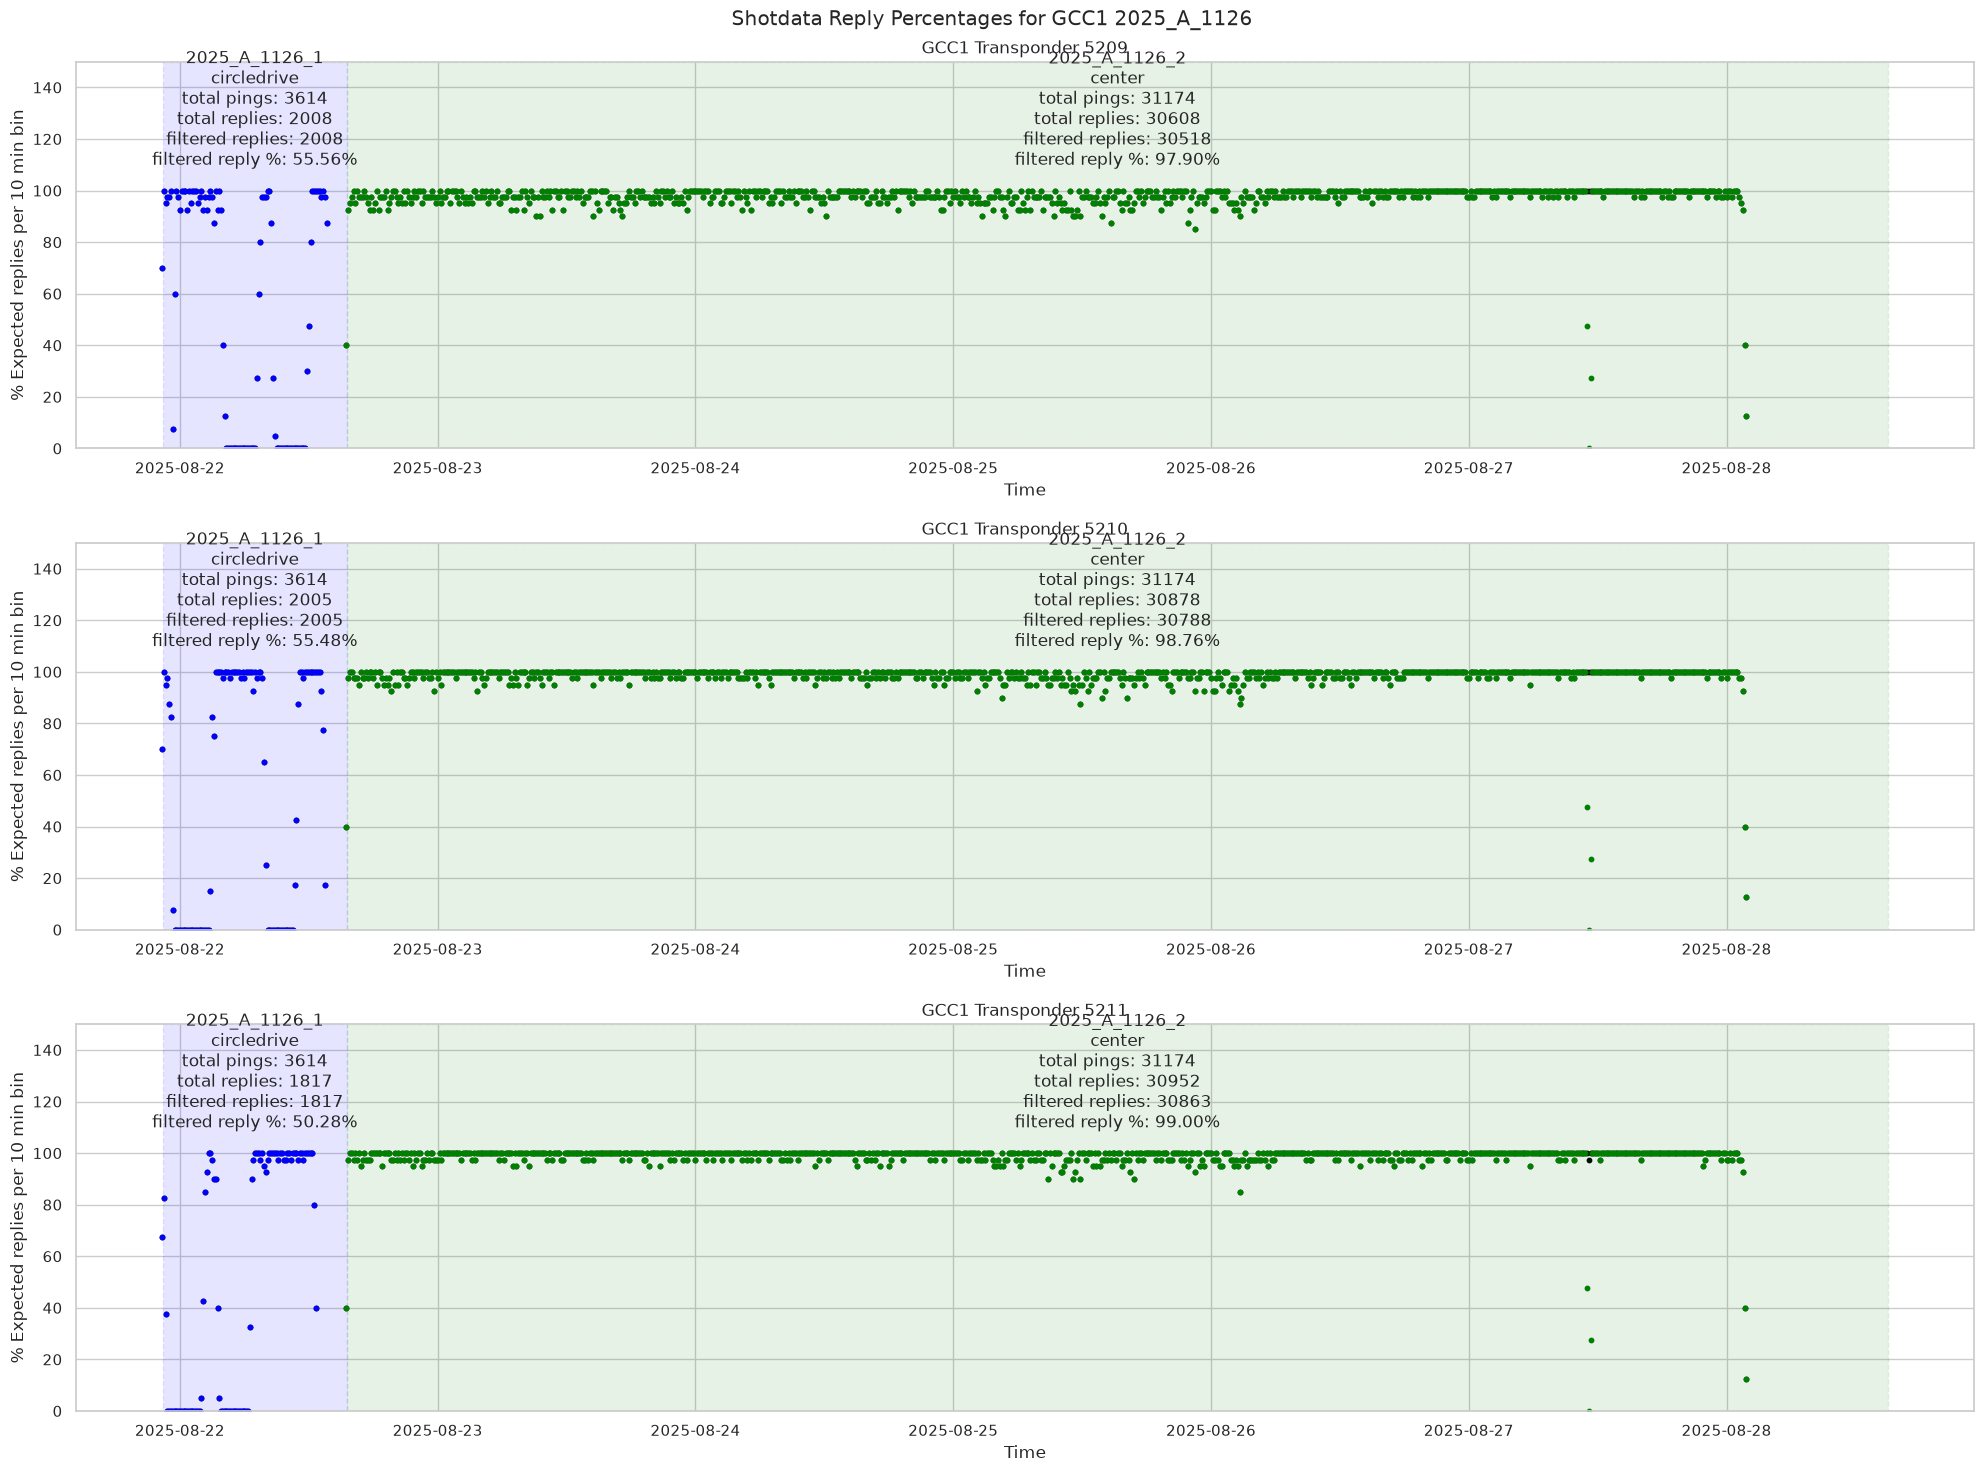

In [9]:
workflow.modeling_plot_shotdata_replies_per_transponder()

## Run Garpos
This will loop through all the surveys in the campaign and run GARPOS on each.  

You can change the inversion parameters and run again to compare results, but make sure to increment `run_id` so that the results are stored in a new directory.

Optional Variables to include in `modeling_run_garpos()`
  * `survey_id`: Optional survey identifier to process. If None, processes all surveys
    * Default: None
  * `run_id`: Identifier for the GARPOS run 
    * Default: "Test"
  * `iterations`: Number of GARPOS iterations to perform. Multiple iterations can improve results, but increases processing runtime.
    * Default: 1  
  * `override`: True/False. If true, re-runs GARPOS even if results exist.
    * Default: False
  * `inversion_params`: Custom GARPOS inversion parameters to apply. Nested under `inversion_params` key.
    * For more information: https://github.com/s-watanabe-jhod/garpos/blob/master/sample/Settings-prep.ini
    * `spline_degree` Default: 3
    * `log_lambda` Smoothness parameter for background perturbation (in log10 scale). Default: [0]
    * `log_gradlambda` Smoothness parameter for spatial gradient ( = Lambda0 * gradLambda ). Default: -1
    * `mu_t` Correlation length of data for transmit time (in min.). Default: [0.0]
    * `mu_mt` Data correlation coefficient b/w the different transponders. Default: [0.5]
    * `knotint0` Typical knot interval (in min.) for gamma's a0 component. Default: 5
    * `knotint1` Typical knot interval (in min.) for gamma's a1 component. Default: 0
    * `knotint2` Typical knot interval (in min.) for gamma's a2 component. Default: 0
    * `rejectcriteria` Criteria for rejection of data (+/- rsig * Sigma). 0 = no rejection. Default: 2
    * `inversiontype` Default: positions. Options: positions, gammas, both
    * `traveltimescale` Typical measurement error for travel time. Default: 1.0e-4
    * `maxloop` Maximum loop for iteration. Default: 50
    * `convcriteria` Convergence criteria for model parameters. Default: 5.0e-3
    * `deltap` Infinitesimal value to make Jacobian matrix. Default: 1.0e-6
    * `deltab` Infinitesimal value to make Jacobian matrix. Default: 1.0e-6

### Set up any custom settings

In [10]:
# Example custom settings for GARPOS inversion
GARPOS_CUSTOM_SETTINGS = {
    'inversion_params' : {
        'maxloop': 5 # Maximum number of inversion loops
        }
    }

### Set up run ID and survey (if needed)

In [11]:
SURVEY_NUMBER = 1
SURVEY_ID=f"{CAMPAIGN}_{SURVEY_NUMBER}"

In [12]:
RUN_ID = "1"   # Change name or number for each GARPOS run to avoid overwriting previous results

### Run garpos with options outlined above

In [ ]:
workflow.modeling_run_garpos(
        run_id=RUN_ID,
        survey_id=None,
        custom_settings=GARPOS_CUSTOM_SETTINGS,
        override=True
    )

Running GARPOS model. Run ID: 1
Running GARPOS model for survey 2025_A_1126_1. Run ID: 1
Iteration 1 of 1 for survey 2025_A_1126_1
Running GARPOS model for GCC1, . Run ID: 1
Dropping 72 of 5830 shots with implausible antenna height (likely a period of degraded GNSS tracking) before running GARPOS: /home/jovyan/cascadia-gorda/GCC1/2025_A_1126/2025_A_1126_1/GARPOS/2025_A_1126_1_circledrive_shotdata_filtered_rectified.csv


  suffix  lamb0  lgrad  mu_t  mu_m
0     _1    1.0    0.1   0.0   0.5
Inversion loop 001, RMS(TT) =  21.497847 ms, used_shot =  84.6%, reject =  887, Max(dX) =    10.0000, Hgt =  -3103.318
Inversion loop 002, RMS(TT) =  16.447450 ms, used_shot =  78.1%, reject = 1260, Max(dX) =    10.0000, Hgt =  -3107.304


## Plot Results

Plot results from GARPOS run(s). 

Optional Parameters
  * `survey_id`: ID of the survey to plot results for
    * Default: None
  * `run_id`: The run ID of the survey results to plot
    * Default: "test"
  * `res_filter`: The residual filter value to filter outrageous values (m).
    * Default: 10
  * `save_fig`: True/False. If true, save the figure created.
    * Default: True
  * `show_fig`: True/False. If true, display figure.
    * Default True

  *For more information on this function, check out our [ReadTheDocs](https://es-sfgtools.readthedocs.io/en/latest/api/es_sfgtools.workflows.workflow_handler.html#es_sfgtools.workflows.workflow_handler.WorkflowHandler.modeling_plot_garpos_results)*


In [ ]:
workflow.modeling_plot_garpos_results(run_id=RUN_ID)

### Plot just the residuals from garpos in their own plot

In [ ]:
#include all data provided as input, and show the removed (flagged) data in blue and the data kept (unflagged) in orange
workflow.modeling_plot_flagged_residuals(run_id=RUN_ID) 

In [ ]:
#Show the residuals for only the data used in the solution
workflow.modeling_plot_garpos_residuals(run_id=RUN_ID) 